# 08 — comparaisons subset

Lit `checkpoints/<run>/history.json` (et `gold_sanity.json` s'il existe).
Même split : **924 train / 653 val**, seed 42.

**Pilote : `RUNS` uniquement.** Commenter une ligne retire un checkpoint.
Pas d'overlays, pas de table `LABELS`. REF = `subset_vit_k_llrd08_det_frac025` s'il est dans `RUNS` (le 224, pas le 320).

**Suivi en cours — CoAt-a rmlp2, distil Original_main, crop145** :
- **coat_a_rmlp2_llrd088_freeze** : `coatnet_rmlp_2` IN-12k, gel 1 epoch, LLRD 0,88 (stem ~4,7e-6, pic 1e-4), re-warmup au dégel. Même split que le distil v20h (1687 / 652). La courbe apparaît à la fin de l'epoch 1.
- Lire l'AUC de l'epoch 2 contre l'epoch 1 gelée (0,722 / gold 0,670). Un dégel qui retombe vers 0,52 = le bas du réseau bouge encore trop. Le run LLRD 0,97 (epoch 1 0,722 puis epoch 2 0,519) est dans `RUNS` pour comparer.

**Suivi en cours — v20h crop145, soft labels expert-stressed v2** (queue en cours, une variante après l'autre) :
- **esv2_soft / calibrated / accuracy / strictmri** : même recette que `v20h … hybrid025_wd01_crop145`, arrêt à **4 epochs** (cosine toujours sur 10, donc le LR des 4 premières epochs reste celui du run de référence). Train = les 1687 UID RSNA du distil (pas d'OAI). Val = les 652 études hybrid, labels officiels. Synovite = label v3b. Les 11 autres cibles viennent du zip. `acc60` est sorti de la file.
- La courbe apparaît dès la fin de l'epoch 1 (`history.json`). Avant, la ligne reste « EN COURS ».
- Lire le Δ val et gold contre le crop145 hybrid (0,9584) et le distil crop145 (0,9609). Δ < 0,01 = bruit.

**Suivi en cours — ConvNeXt-T, stride 32** (DINOv3, puis IN-22k dès qu'il se termine) :
- **cnx_a_dinov3_llrd086** : ConvNeXt-T `dinov3_lvd1689m`, carte 7×7, graphe v20h, hybrid025. Le run stride 16 (val 0,616 puis 0,623) est écarté : `history.json` et les checkpoints ont été supprimés, les courbes ne le montrent plus.
- **cnx_a_in22k_llrd086** : mêmes réglages, poids `fb_in22k_ft_in1k`. La courbe apparaît quand son `history.json` existe, donc après la fin du DINOv3.
- Epoch 1 : val sous 0,70 = bug (CoAt-a était à 0,757 sur ce split). Fin de run : val ≥ 0,924 (ViT-k) et ACL / MCL au-dessus de ViT-k de plus de 0,01.

Autres runs (hors `RUNS`) :
- **v20b_det** : CNN déterministe, terminé. val **0,8364** / gold **0,8842** @ ep10.
- **v20b320_320** : même recette que v20b_det, entrée 320. Arrêté ep2 : val **0,7023** / gold **0,6882**.
- **coat_a_llrd08_det** : parent CoAt (LLRD 0,8). Arrêté ep6 : **0,7913 / 0,7894**.
- **coat_a_llrd07_det** : LLRD 0,7. Terminé, early stop ep11. Best **0,7947 / 0,7916** @ ep7. Pas un gain.
- **coat_b_llrd09_det** : LLRD 0,9. Arrêté ep4 : **0,7507 / 0,7281**. Sous le parent.
- **coat_d_mid14_det** : CAM stage 2 14×14. Terminé, early stop ep11. Best **0,8003 / 0,8111** @ ep7. `mid_proj_l1` ~ 0,002 (branche vivante, faible).
- **coat_c_kd_v20b_det** : KD v20b (ACL, MCL, MM, PF OA, Baker's, Fracture). **En cours**, ep6 **0,8138 / 0,8473**. Devant coat_a à epoch égale.
- **v20h_ssl_ep6 / ep10 / ep15 / ep20** : v20h, encodeur SimCLR à ces epochs, labels Coolin `targets_v3b`. La val AUC n'est pas comparable à v20b_det (soft labels binarisés à 0,5). Lire le **gold**, et la val entre ces runs et **v20b_det_v3b** (même CSV, sans SSL). ep10, ep15 et ep20 apparaissent dès que leur `history.json` existe.
- **v20h_det** : v20h, RadImageNet, labels gpt56sol, seed 42. Témoin sans SSL.
- **v20h_dino_ep11** : même recette que v20h_det, encodeur DINO epoch 11. Comparable en val et en gold à v20h_det (delta > 0,01). La courbe apparaît dès que `history.json` existe.
- **v20h_dino_ep6** : même recette, encodeur DINO epoch 6. Même comparaison.
- **v20h_dino_ep29** : même recette, encodeur DINO epoch 29. Même comparaison.
- **vit_k_llrd08_det** : baseline ViT-k LLRD 0,8, labels gpt56sol, DINOv3 brut. Référence de l'ablation encodeur.
- **vit_k_llrd08_det_dino_ep13** : même recette, encodeur DINO epoch 13. Comparable en val et en gold à vit_k_llrd08_det (delta > 0,01). La courbe apparaît dès que `history.json` existe.

CoAt n'est un successeur **macro** que s'il bat v20b_det de plus de 0,01
en val **et** gold. Sinon le lire en **spécialiste**. Δ **&lt; 0,01** = bruit.
Gold n=58, jamais pour le checkpoint.

Relancer **load → graphes** pendant un train : `history.json` s'écrit à la fin de chaque époque. cnx_a_dinov3 reste « en cours » tant que l'époque 1 n'est pas finie.


In [243]:
from __future__ import annotations

import json
from datetime import datetime
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.dpi"] = 100

ROOT = Path.cwd() if (Path.cwd() / "checkpoints").exists() else Path.cwd().parent
CKPT = ROOT / "checkpoints"

# Seul levier du notebook : commenter une ligne pour exclure un run.
# REF = subset_vit_k_llrd08_det_frac025 (224) s'il est dans RUNS, pas le run 320.
RUNS = [
    # hybrid025 : meme val 652 RSNA, train 1265 RSNA + 422 OAI, 7 epochs.
    "subset_v20h_dino_ep11_v3b_hybrid025",
    # wd 0.01, dropout 0.2, 8 epochs, cosine 10. Meme split que v20h hybrid025.

    "subset_vit_k_llrd08_320_v3b_hybrid025",
    # CNX-a stride 32, carte 7x7. Le stride 16 (val 0.62) est jete.
    "subset_cnx_r7_in22k_v3b_hybrid025",
    "subset_v20h_dino_ep11_v3b_rsna1687_distil_main_crop145",
    # Soft labels expert-stressed v2. Memes 1687 UID RSNA que le distil,
    # val hybrid officielle. La courbe apparait des la fin de l'epoch 1.
    "subset_v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145",
    "subset_coat_a_rmlp2_crop145_rsna1687_distil_main",
    # rmlp2, gel 1 epoch, LLRD 0.88, re-warmup. Courbe des la fin de l'epoch 1.
    "subset_coat_a_rmlp2_llrd088_freeze_crop145_rsna1687_distil_main",
    "subset_coat_a_llrd08_v3b_hybrid025"
]

TARGETS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA",
    "Lateral OA", "PF OA", "Effusion", "Synovitis", "Baker's",
    "Contusion", "Fracture",
]
# Fallback si aucun run ne bat la REF de > 0.01 (debut de train).
DEFAULT_SPECIALIST = ["Contusion", "Effusion", "Baker's", "ACL"]
NOISE = 0.01


def run_label(name: str) -> str:
    s = name[7:] if name.startswith("subset_") else name
    return s.replace("_crop130", "").replace("_frac025", "")


print("ROOT", ROOT)
print("RUNS", RUNS)


ROOT c:\Users\sulta\Documents\RSNA-comp
RUNS ['subset_v20h_dino_ep11_v3b_hybrid025', 'subset_vit_k_llrd08_320_v3b_hybrid025', 'subset_cnx_r7_in22k_v3b_hybrid025', 'subset_v20h_dino_ep11_v3b_rsna1687_distil_main_crop145', 'subset_v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145', 'subset_coat_a_rmlp2_crop145_rsna1687_distil_main', 'subset_coat_a_rmlp2_llrd088_freeze_crop145_rsna1687_distil_main', 'subset_coat_a_llrd08_v3b_hybrid025']


In [244]:
def load_run(name: str) -> dict | None:
    d = CKPT / name
    hist_p = d / "history.json"
    if not hist_p.exists():
        log_p = d / "train.log"
        if not log_p.exists():
            alt = ROOT / "logs" / f"{name}.log"
            if alt.exists():
                log_p = alt
        uid_p = d / "train_uids.txt"
        if log_p.exists() or uid_p.exists():
            stamp = ""
            if log_p.exists():
                stamp = datetime.fromtimestamp(log_p.stat().st_mtime).strftime("%H:%M")
            print(
                f"  {run_label(name)}: EN COURS | pas encore de history.json "
                f"(écrit en fin d'époque) | log {stamp or '?'}"
            )
        else:
            print(f"  skip {run_label(name)} : pas de history.json")
        return None
    hist = pd.DataFrame(json.loads(hist_p.read_text(encoding="utf-8")))
    if hist.empty:
        print(f"  skip {run_label(name)} : history.json vide")
        return None
    gold = None
    gp = d / "gold_sanity.json"
    if gp.exists():
        gold = json.loads(gp.read_text(encoding="utf-8"))
    uids = []
    up = d / "train_uids.txt"
    if up.exists():
        uids = [ln.strip() for ln in up.read_text(encoding="utf-8").splitlines() if ln.strip()]
    best_idx = hist["val_macro_auc"].idxmax()
    best_row = hist.loc[best_idx]
    gold_best = None
    if "gold_macro_auc" in hist.columns and pd.notna(best_row.get("gold_macro_auc")):
        gold_best = float(best_row["gold_macro_auc"])
    return {
        "name": name,
        "label": run_label(name),
        "dir": d,
        "hist": hist,
        "gold": gold,
        "uids": uids,
        "done": gp.exists(),
        "best_epoch": int(best_row["epoch"]),
        "best_val": float(best_row["val_macro_auc"]),
        "best_gold": gold_best,
        "last_epoch": int(hist["epoch"].max()),
        "n_epochs": int(len(hist)),
    }


def line_kw(r: dict) -> dict:
    return dict(marker="o", label=r["label"])


runs = []
print("runs demandes :", [run_label(n) for n in RUNS])
for name in RUNS:
    rec = load_run(name)
    if rec is None:
        continue
    runs.append(rec)
    gold_txt = f"gold {rec['best_gold']:.3f}" if rec["best_gold"] is not None else "gold n/a"
    etat = "termine" if rec["done"] else f"{rec['n_epochs']} epochs"
    print(
        f"  {rec['label']}: {etat} | best val {rec['best_val']:.4f} "
        f"@ ep {rec['best_epoch']} | {gold_txt} | n_train {len(rec['uids']) or '?'}"
    )

if not runs:
    raise SystemExit("aucun history.json — lance d'abord un train subset")

REF = next(
    (n for n in RUNS if n == "subset_vit_k_llrd08_det_frac025"),
    next(
        (n for n in RUNS if "vit_k" in n and "320" not in n and "dino" not in n),
        next((n for n in RUNS if "v20b" in n and "320" not in n), runs[0]["name"]),
    ),
)
print("REF", run_label(REF))


runs demandes : ['v20h_dino_ep11_v3b_hybrid025', 'vit_k_llrd08_320_v3b_hybrid025', 'cnx_r7_in22k_v3b_hybrid025', 'v20h_dino_ep11_v3b_rsna1687_distil_main_crop145', 'v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145', 'coat_a_rmlp2_crop145_rsna1687_distil_main', 'coat_a_rmlp2_llrd088_freeze_crop145_rsna1687_distil_main', 'coat_a_llrd08_v3b_hybrid025']
  v20h_dino_ep11_v3b_hybrid025: termine | best val 0.9551 @ ep 7 | gold 0.912 | n_train 1687
  vit_k_llrd08_320_v3b_hybrid025: 7 epochs | best val 0.9199 @ ep 7 | gold 0.841 | n_train ?
  cnx_r7_in22k_v3b_hybrid025: termine | best val 0.9311 @ ep 7 | gold 0.891 | n_train 1687
  v20h_dino_ep11_v3b_rsna1687_distil_main_crop145: 7 epochs | best val 0.9609 @ ep 7 | gold 0.916 | n_train 1687
  v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145: termine | best val 0.9511 @ ep 4 | gold 0.909 | n_train 1687
  coat_a_rmlp2_crop145_rsna1687_distil_main: 2 epochs | best val 0.5359 @ ep 1 | gold 0.507 | n_train 1687
  coat_a_rmlp2_llrd088_freeze_crop14

## Tableau résumé

Meilleure epoch = argmax de la val macro-AUC (comme le `best.pt`).


In [245]:
rows = []
for r in runs:
    last = r["hist"].iloc[-1]
    rows.append({
        "run": r["label"],
        "name": r["name"],
        "etat": "termine" if r["done"] else f"{r['n_epochs']} ep",
        "n_train": len(r["uids"]) or None,
        "best_epoch": r["best_epoch"],
        "best_val_auc": r["best_val"],
        "best_gold_auc": r["best_gold"],
        "last_train_loss": float(last["loss"]),
        "last_val_loss": float(last["val_loss"]) if "val_loss" in last else None,
        "last_val_auc": float(last["val_macro_auc"]),
    })
summary = pd.DataFrame(rows).set_index("run")
display(summary.drop(columns=["name"]).round(4))

ref_row = next((row for _, row in summary.iterrows() if row["name"] == REF), None)
if ref_row is not None and len(summary) > 1:
    print("\ndelta vs", run_label(REF), "(best val AUC)")
    for lab, row in summary.iterrows():
        if row["name"] == REF:
            continue
        d = row["best_val_auc"] - ref_row["best_val_auc"]
        print(f"  {lab}: {d:+.4f}  {'(bruit, <0.01)' if abs(d) < NOISE else ''}")


,etat,n_train,best_epoch,best_val_auc,best_gold_auc,last_train_loss,last_val_loss,last_val_auc
run,,,,,,,,
v20h_dino_ep11_v3b_hybrid025,termine,1687.0,7,0.9551,0.9124,0.3401,0.3558,0.9551
vit_k_llrd08_320_v3b_hybrid025,7 ep,NaN,7,0.9199,0.8409,0.3446,0.3773,0.9199
cnx_r7_in22k_v3b_hybrid025,termine,1687.0,7,0.9311,0.8910,0.3286,0.3624,0.9311
v20h_dino_ep11_v3b_rsna1687_distil_main_crop145,7 ep,1687.0,7,0.9609,0.9160,0.4358,0.3478,0.9609
v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145,termine,1687.0,4,0.9511,0.9088,0.3390,0.3931,0.9511
coat_a_rmlp2_crop145_rsna1687_distil_main,2 ep,1687.0,1,0.5359,0.5067,0.6727,0.5079,0.5112
coat_a_rmlp2_llrd088_freeze_crop145_rsna1687_distil_main,1 ep,1687.0,1,0.7215,0.6698,0.6538,0.4720,0.7215
coat_a_llrd08_v3b_hybrid025,termine,1687.0,7,0.9041,0.8591,0.3559,0.3851,0.9041



delta vs v20h_dino_ep11_v3b_hybrid025 (best val AUC)
  vit_k_llrd08_320_v3b_hybrid025: -0.0352  
  cnx_r7_in22k_v3b_hybrid025: -0.0241  
  v20h_dino_ep11_v3b_rsna1687_distil_main_crop145: +0.0057  (bruit, <0.01)
  v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145: -0.0040  (bruit, <0.01)
  coat_a_rmlp2_crop145_rsna1687_distil_main: -0.4193  
  coat_a_rmlp2_llrd088_freeze_crop145_rsna1687_distil_main: -0.2337  
  coat_a_llrd08_v3b_hybrid025: -0.0511  


## Courbes (tous les runs superposés)

courbes v20h_dino_ep11_v3b_hybrid025: epochs [1, 2, 3, 4, 5, 6, 7]
courbes vit_k_llrd08_320_v3b_hybrid025: epochs [1, 2, 3, 4, 5, 6, 7]
courbes cnx_r7_in22k_v3b_hybrid025: epochs [1, 2, 3, 4, 5, 6, 7]
courbes v20h_dino_ep11_v3b_rsna1687_distil_main_crop145: epochs [1, 2, 3, 4, 5, 6, 7]
courbes v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145: epochs [1, 2, 3, 4]
courbes coat_a_rmlp2_crop145_rsna1687_distil_main: epochs [1, 2]
courbes coat_a_rmlp2_llrd088_freeze_crop145_rsna1687_distil_main: epochs [1]
courbes coat_a_llrd08_v3b_hybrid025: epochs [1, 2, 3, 4, 5, 6, 7]


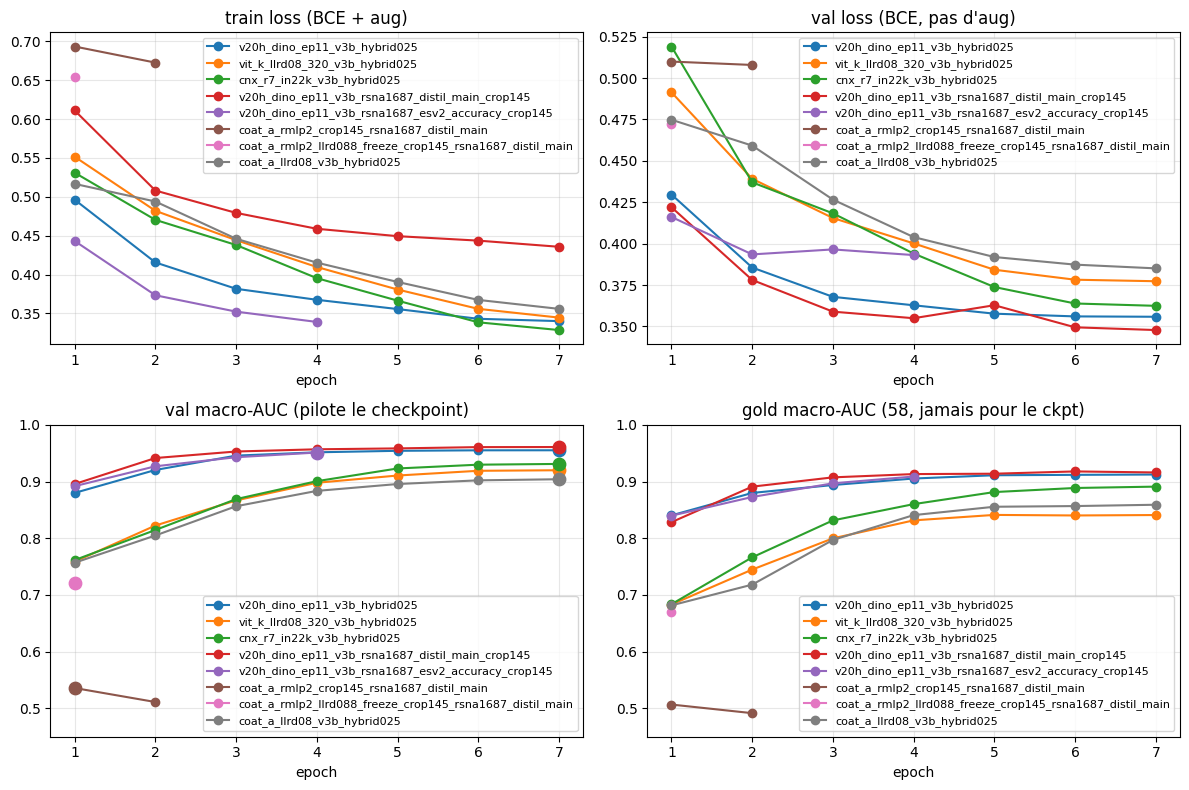

In [246]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for r in runs:
    h = r["hist"].sort_values("epoch")
    kw = line_kw(r)
    print(f"courbes {r['label']}: epochs {list(map(int, h.epoch))}")
    axes[0, 0].plot(h.epoch, h.loss, **kw)
    if "val_loss" in h.columns:
        axes[0, 1].plot(h.epoch, h.val_loss, **kw)
    axes[1, 0].plot(h.epoch, h.val_macro_auc, **kw)
    if "gold_macro_auc" in h.columns:
        axes[1, 1].plot(h.epoch, h.gold_macro_auc, **kw)
    axes[1, 0].scatter([r["best_epoch"]], [r["best_val"]], s=80, zorder=5)

emax = max(int(r["hist"]["epoch"].max()) for r in runs)
axes[0, 0].set_title("train loss (BCE + aug)")
axes[0, 1].set_title("val loss (BCE, pas d'aug)")
axes[1, 0].set_title("val macro-AUC (pilote le checkpoint)")
axes[1, 1].set_title("gold macro-AUC (58, jamais pour le ckpt)")
for ax in axes.ravel():
    ax.set_xlabel("epoch")
    ax.set_xticks(range(1, emax + 1))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
axes[1, 0].set_ylim(0.45, 1.0)
axes[1, 1].set_ylim(0.45, 1.0)
plt.tight_layout()
plt.show()


## Écart-type des probabilités (val)

Dispersion des scores de validation. Std qui se replie pendant que l'AUC baisse = effondrement (`coat_a_det`, epoch 3). Std qui plonge au dégel puis revient avec l'AUC = choc récupéré (LLRD, epoch 2).

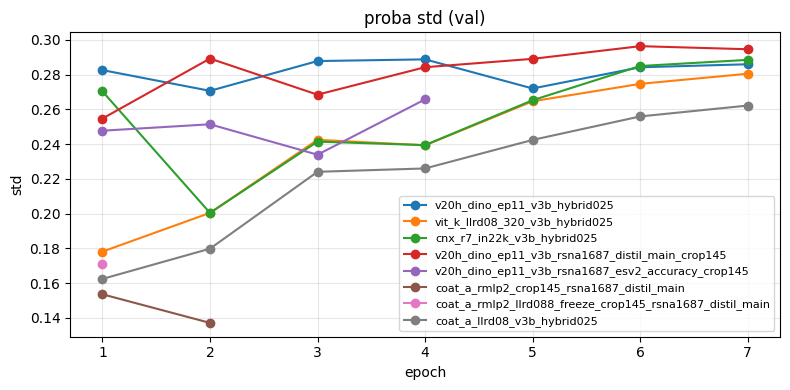

In [247]:
fig, ax = plt.subplots(figsize=(8, 4))
emax_std = max(int(r["hist"]["epoch"].max()) for r in runs)
for r in runs:
    h = r["hist"].sort_values("epoch")
    if "proba_std" not in h.columns:
        print(f"  {r['label']}: pas de proba_std")
        continue
    ax.plot(h.epoch, h.proba_std, **line_kw(r))
ax.set_title("proba std (val)")
ax.set_xlabel("epoch")
ax.set_ylabel("std")
ax.set_xticks(range(1, emax_std + 1))
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Suivi à epoch égale : v20h esv2 vs crop145

`LIVES` = les 5 v20h crop145 entraînés sur les soft labels du zip.
`PARENT` = `v20h … hybrid025_wd01_crop145` (même recette, train hybrid).
`DISTIL` = `v20h … rsna1687_distil_main_crop145` (mêmes 1687 UID, labels v3b + teacher).
Δ à epoch égale. Au-delà de la dernière epoch du repère, Δ vs cette dernière epoch.
Relancer cette cellule après chaque epoch : sans `history.json`, la ligne reste « pas encore ».


=== v20h_dino_ep11_v3b_rsna1687_esv2_soft_crop145 ===
pas encore de history.json (ecrit en fin d'epoch 1)

=== v20h_dino_ep11_v3b_rsna1687_esv2_calibrated_crop145 ===
pas encore de history.json (ecrit en fin d'epoch 1)

=== v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145 ===


,v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145 val,v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145 gold,v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145 std,v20h_dino_ep11_v3b_rsna1687_distil_main_crop145 val,v20h_dino_ep11_v3b_rsna1687_distil_main_crop145 gold,v20h_dino_ep11_v3b_rsna1687_distil_main_crop145 std,v20h_dino_ep11_v3b_hybrid025 val,v20h_dino_ep11_v3b_hybrid025 gold,v20h_dino_ep11_v3b_hybrid025 std,Δval vs v20h_dino_ep11_v3b_rsna1687_distil_main_crop145,Δgold vs v20h_dino_ep11_v3b_rsna1687_distil_main_crop145,Δval vs v20h_dino_ep11_v3b_hybrid025,Δgold vs v20h_dino_ep11_v3b_hybrid025
epoch,,,,,,,,,,,,,
1,0.8918,0.8398,0.2478,0.8956,0.8284,0.2548,0.8800,0.8403,0.2827,-0.0038,+0.0114,+0.0119,-0.0005
2,0.9269,0.8728,0.2515,0.9415,0.8910,0.2893,0.9204,0.8799,0.2707,-0.0146,-0.0182,+0.0065,-0.0071
3,0.9429,0.8969,0.2340,0.9530,0.9074,0.2685,0.9457,0.8939,0.2879,-0.0101,-0.0105,-0.0028,+0.0030
4,0.9511,0.9088,0.2658,0.9569,0.9132,0.2843,0.9516,0.9053,0.2888,-0.0057,-0.0043,-0.0004,+0.0035


4 epoch(s) | best val 0.9511 @ ep 4
ep 4 vs v20h_dino_ep11_v3b_rsna1687_distil_main_crop145 ep 4 : Δval -0.0057 | Δgold -0.0043
ep 4 vs v20h_dino_ep11_v3b_hybrid025 : Δval -0.0004 | Δgold +0.0035

=== v20h_dino_ep11_v3b_rsna1687_esv2_strictmri_crop145 ===
pas encore de history.json (ecrit en fin d'epoch 1)


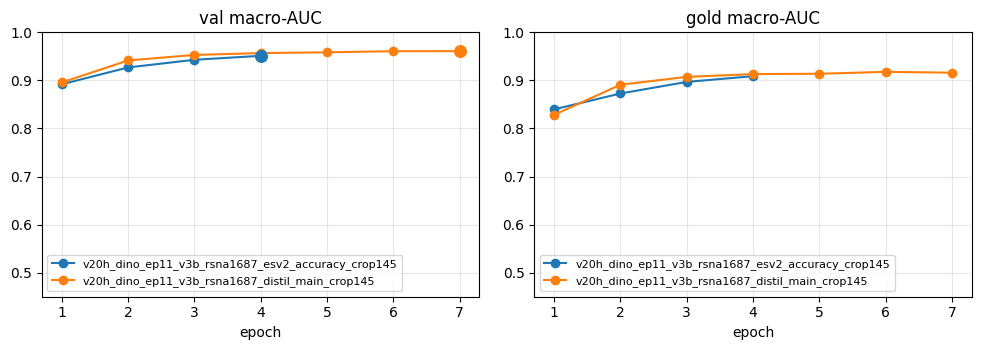

In [248]:
LIVES = [
    "subset_v20h_dino_ep11_v3b_rsna1687_esv2_soft_crop145",
    "subset_v20h_dino_ep11_v3b_rsna1687_esv2_calibrated_crop145",
    "subset_v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145",
    "subset_v20h_dino_ep11_v3b_rsna1687_esv2_strictmri_crop145",
]
PARENT = "subset_v20h_dino_ep11_v3b_hybrid025_wd01_crop145"
DISTIL = "subset_v20h_dino_ep11_v3b_rsna1687_distil_main_crop145"
DEAD_STD = 0.12

by_name = {r["name"]: r for r in runs}
METRICS = [("val_macro_auc", "val"), ("gold_macro_auc", "gold"), ("proba_std", "std")]


def per_epoch(name: str) -> pd.DataFrame | None:
    r = by_name.get(name)
    if r is None:
        return None
    return r["hist"].set_index("epoch")


def kd_targets(name: str) -> list[str]:
    p = CKPT / name / "distil.json"
    if not p.exists():
        return []
    return list(json.loads(p.read_text(encoding="utf-8")).get("targets", []))


def track_live(live_name: str) -> None:
    live = per_epoch(live_name)
    parent, distil, ref = per_epoch(PARENT), per_epoch(DISTIL), per_epoch(REF)
    print(f"\n=== {run_label(live_name)} ===")
    if live is None:
        print("pas encore de history.json (ecrit en fin d'epoch 1)")
        return
    cols = {}
    for name, h in [(live_name, live), (PARENT, parent), (DISTIL, distil), (REF, ref)]:
        if h is None:
            continue
        for m, short in METRICS:
            cols[f"{run_label(name)} {short}"] = h[m].reindex(live.index)
    track = pd.DataFrame(cols)
    for name, h in [(PARENT, parent), (DISTIL, distil), (REF, ref)]:
        if h is None:
            continue
        for m, short in METRICS[:2]:
            track[f"Δ{short} vs {run_label(name)}"] = live[m] - h[m].reindex(live.index)
    if "distil_loss" in live.columns:
        track["kd loss"] = live["distil_loss"]
    if "mid_proj_l1" in live.columns:
        track["mid_proj_l1"] = live["mid_proj_l1"]
    delta_cols = [c for c in track.columns if c.startswith("Δ")]
    display(
        track.style.format("{:.4f}", na_rep="—")
        .format("{:+.4f}", subset=delta_cols, na_rep="—")
        .background_gradient(cmap="RdYlGn", vmin=-0.05, vmax=0.05, subset=delta_cols)
    )

    last = int(live.index.max())
    print(f"{last} epoch(s) | best val {live.val_macro_auc.max():.4f} "
          f"@ ep {int(live.val_macro_auc.idxmax())}")
    if "coat" in live_name and 3 in live.index and 1 in live.index:
        dead = (live.val_macro_auc[3] < live.val_macro_auc[1]
                and live.proba_std[3] < DEAD_STD)
        print("controle ep3 :", "MORT (signature lr uniforme) -> couper le train"
              if dead else "vivant (pas la signature lr uniforme)")
    for tag, base in ((PARENT, parent), (DISTIL, distil)):
        if base is None:
            continue
        p_ep = last if last in base.index else int(base.index.max())
        dv = live.val_macro_auc[last] - base.val_macro_auc[p_ep]
        dg = live.gold_macro_auc[last] - base.gold_macro_auc[p_ep]
        note = "" if p_ep == last else f" (repere arrete ep {p_ep})"
        print(f"ep {last} vs {run_label(tag)} ep {p_ep}{note} : "
              f"Δval {dv:+.4f} | Δgold {dg:+.4f}")
    if ref is not None and last in ref.index:
        dv = live.val_macro_auc[last] - ref.val_macro_auc[last]
        dg = live.gold_macro_auc[last] - ref.gold_macro_auc[last]
        print(f"ep {last} vs {run_label(REF)} : Δval {dv:+.4f} | Δgold {dg:+.4f}")

    kd = kd_targets(live_name)
    if kd and parent is not None:
        ep = min(last, int(parent.index.max()))
        rows = []
        for t in TARGETS:
            col = f"auc_{t}"
            if col in live.columns and col in parent.columns:
                rows.append({"cible": t, "KD": "oui" if t in kd else "non",
                             "Δ vs parent": live.loc[ep, col] - parent.loc[ep, col]})
        kd_df = pd.DataFrame(rows)
        means = kd_df.groupby("KD")["Δ vs parent"].mean()
        print(f"KD ep {ep} vs {run_label(PARENT)} : Δ moyen cibles distillees "
              f"{means.get('oui', float('nan')):+.4f} | non distillees "
              f"{means.get('non', float('nan')):+.4f}")
        display(
            kd_df.set_index("cible").style.format({"Δ vs parent": "{:+.4f}"})
            .background_gradient(cmap="RdYlGn", vmin=-0.05, vmax=0.05,
                                 subset=["Δ vs parent"])
        )


for name in LIVES:
    track_live(name)

# Courbes des 5 esv2 des qu'une epoch est ecrite, plus les deux reperes.
focus = list(dict.fromkeys(
    n for n in (*LIVES, PARENT, DISTIL) if n in by_name
))
if focus:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True)
    emax_f = max(int(by_name[n]["hist"]["epoch"].max()) for n in focus)
    for name in focus:
        h = by_name[name]["hist"].sort_values("epoch")
        kw = line_kw(by_name[name])
        axes[0].plot(h.epoch, h.val_macro_auc, **kw)
        if "gold_macro_auc" in h.columns:
            axes[1].plot(h.epoch, h.gold_macro_auc, **kw)
        axes[0].scatter(
            [by_name[name]["best_epoch"]], [by_name[name]["best_val"]],
            s=70, zorder=5,
        )
    axes[0].set_title("val macro-AUC")
    axes[1].set_title("gold macro-AUC")
    for ax in axes:
        ax.set_xlabel("epoch")
        ax.set_xticks(range(1, emax_f + 1))
        ax.set_ylim(0.45, 1.0)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## AUC par cible à la meilleure epoch

Barres = les 12 findings. En **gras** : un run y est **spécialiste** (bat la REF de &gt; 0,01).


specialiste vs v20h_dino_ep11_v3b_hybrid025 (Δ > 0.01) : ['ACL', 'Lateral OA', 'Effusion', 'Synovitis', 'Fracture']


,subset_v20h_dino_ep11_v3b_hybrid025,subset_vit_k_llrd08_320_v3b_hybrid025,subset_cnx_r7_in22k_v3b_hybrid025,subset_v20h_dino_ep11_v3b_rsna1687_distil_main_crop145,subset_v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145,subset_coat_a_rmlp2_crop145_rsna1687_distil_main,subset_coat_a_rmlp2_llrd088_freeze_crop145_rsna1687_distil_main,subset_coat_a_llrd08_v3b_hybrid025,d_subset_vit_k_llrd08_320_v3b_hybrid025,d_subset_cnx_r7_in22k_v3b_hybrid025,d_subset_v20h_dino_ep11_v3b_rsna1687_distil_main_crop145,d_subset_v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145,d_subset_coat_a_rmlp2_crop145_rsna1687_distil_main,d_subset_coat_a_rmlp2_llrd088_freeze_crop145_rsna1687_distil_main,d_subset_coat_a_llrd08_v3b_hybrid025
ACL,0.952000,0.891000,0.915000,0.975000,0.958000,0.634000,0.586000,0.832000,-0.061000,-0.037000,0.023000,0.007000,-0.318000,-0.366000,-0.120000
MCL,0.955000,0.775000,0.790000,0.947000,0.933000,0.476000,0.608000,0.770000,-0.180000,-0.165000,-0.009000,-0.022000,-0.479000,-0.347000,-0.185000
Medial Meniscus,0.981000,0.968000,0.985000,0.985000,0.981000,0.525000,0.758000,0.946000,-0.013000,0.003000,0.003000,-0.001000,-0.456000,-0.223000,-0.036000
Lateral Meniscus,0.962000,0.907000,0.939000,0.968000,0.950000,0.530000,0.667000,0.858000,-0.055000,-0.023000,0.006000,-0.012000,-0.433000,-0.295000,-0.105000
Medial OA,0.970000,0.932000,0.963000,0.971000,0.965000,0.581000,0.858000,0.939000,-0.038000,-0.007000,0.001000,-0.005000,-0.390000,-0.112000,-0.031000
Lateral OA,0.937000,0.918000,0.938000,0.956000,0.947000,0.438000,0.809000,0.917000,-0.019000,0.001000,0.019000,0.010000,-0.499000,-0.128000,-0.020000
PF OA,0.903000,0.844000,0.856000,0.907000,0.890000,0.560000,0.753000,0.841000,-0.059000,-0.046000,0.004000,-0.013000,-0.343000,-0.150000,-0.062000
Effusion,0.947000,0.961000,0.960000,0.959000,0.950000,0.410000,0.850000,0.959000,0.013000,0.012000,0.012000,0.003000,-0.537000,-0.097000,0.012000
Synovitis,0.937000,0.949000,0.919000,0.941000,0.939000,0.594000,0.816000,0.926000,0.012000,-0.019000,0.004000,0.001000,-0.344000,-0.121000,-0.011000
Baker's,0.977000,0.950000,0.960000,0.979000,0.969000,0.576000,0.732000,0.950000,-0.027000,-0.018000,0.002000,-0.009000,-0.401000,-0.245000,-0.028000


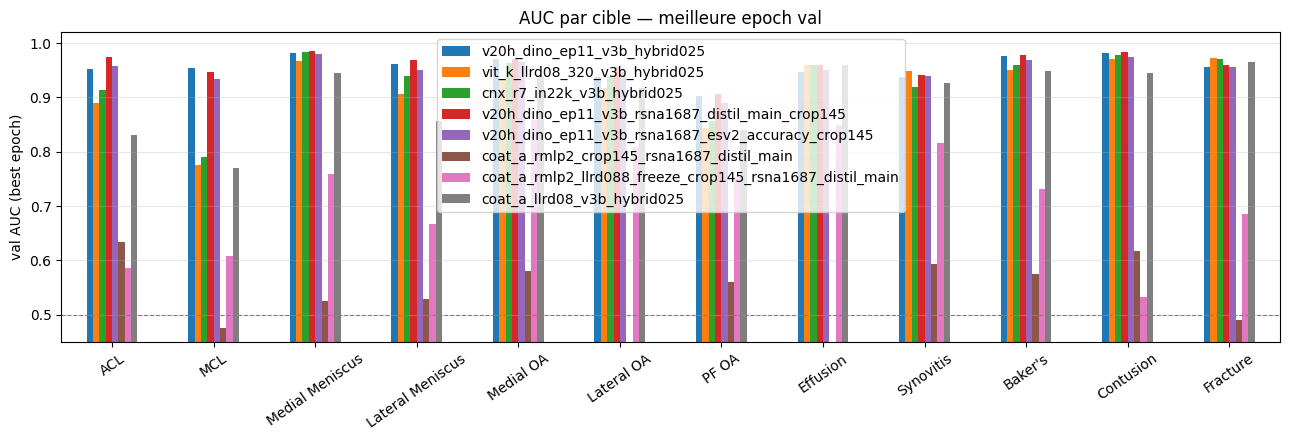

In [249]:
per = {}
for r in runs:
    row = r["hist"].loc[r["hist"]["val_macro_auc"].idxmax()]
    per[r["name"]] = {t: float(row[f"auc_{t}"]) for t in TARGETS if f"auc_{t}" in row.index}
per_df = pd.DataFrame(per).reindex(TARGETS)

vit_names = [r["name"] for r in runs if r["name"] != REF]
FOCUS = list(DEFAULT_SPECIALIST)
if REF in per_df.columns and vit_names:
    FOCUS = []
    for t in TARGETS:
        dmax = float((per_df.loc[t, vit_names] - per_df.loc[t, REF]).max())
        if dmax > NOISE:
            FOCUS.append(t)
    if not FOCUS:
        FOCUS = list(DEFAULT_SPECIALIST)
        print(f"aucun specialiste > 0.01 vs {run_label(REF)} (train trop tot ?) → fallback", FOCUS)
    else:
        print(f"specialiste vs {run_label(REF)} (Δ > 0.01) :", FOCUS)

if REF in per_df.columns:
    for c in [x for x in per_df.columns if x != REF]:
        per_df[f"d_{c}"] = per_df[c] - per_df[REF]

display(per_df.round(3).style.apply(
    lambda s: ["font-weight: bold" if s.name in FOCUS else "" for _ in s],
    axis=1,
))

plot_df = per_df[[r["name"] for r in runs]].rename(
    columns={r["name"]: r["label"] for r in runs}
)
ax = plot_df.plot(kind="bar", figsize=(13, 4.5), rot=35)
ax.set_ylabel("val AUC (best epoch)")
ax.set_ylim(0.45, 1.02)
ax.set_title("AUC par cible — meilleure epoch val")
ax.axhline(0.5, color="gray", lw=0.8, ls="--")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## Delta par cible vs la REF

Positif = le run bat la REF (ViT-k 224). Rouge = spécialiste. Δ &lt; 0,01 = bruit.


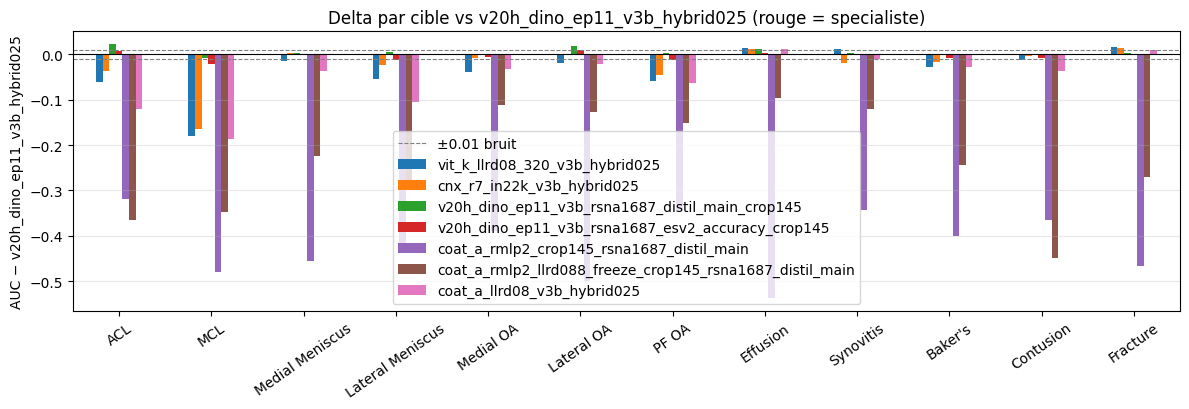

specialiste (val best epoch) :


,subset_v20h_dino_ep11_v3b_hybrid025,subset_vit_k_llrd08_320_v3b_hybrid025,subset_cnx_r7_in22k_v3b_hybrid025,subset_v20h_dino_ep11_v3b_rsna1687_distil_main_crop145,subset_v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145,subset_coat_a_rmlp2_crop145_rsna1687_distil_main,subset_coat_a_rmlp2_llrd088_freeze_crop145_rsna1687_distil_main,subset_coat_a_llrd08_v3b_hybrid025,d_subset_vit_k_llrd08_320_v3b_hybrid025,d_subset_cnx_r7_in22k_v3b_hybrid025,d_subset_v20h_dino_ep11_v3b_rsna1687_distil_main_crop145,d_subset_v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145,d_subset_coat_a_rmlp2_crop145_rsna1687_distil_main,d_subset_coat_a_rmlp2_llrd088_freeze_crop145_rsna1687_distil_main,d_subset_coat_a_llrd08_v3b_hybrid025
ACL,0.952,0.891,0.915,0.975,0.958,0.634,0.586,0.832,-0.061,-0.037,0.023,0.007,-0.318,-0.366,-0.120
Lateral OA,0.937,0.918,0.938,0.956,0.947,0.438,0.809,0.917,-0.019,0.001,0.019,0.010,-0.499,-0.128,-0.020
Effusion,0.947,0.961,0.960,0.959,0.950,0.410,0.850,0.959,0.013,0.012,0.012,0.003,-0.537,-0.097,0.012
Synovitis,0.937,0.949,0.919,0.941,0.939,0.594,0.816,0.926,0.012,-0.019,0.004,0.001,-0.344,-0.121,-0.011
Fracture,0.957,0.973,0.971,0.959,0.957,0.491,0.686,0.966,0.016,0.014,0.003,0.000,-0.466,-0.271,0.009


In [250]:
delta_cols = [c for c in per_df.columns if c.startswith("d_")]
if not delta_cols:
    print(f"pas de delta : il faut REF={run_label(REF)!r} dans RUNS et charge.")
else:
    fig, ax = plt.subplots(figsize=(12, 4.2))
    d = per_df[delta_cols].copy()
    d.columns = [run_label(c[2:]) for c in d.columns]
    colors = ["#c44e52" if t in FOCUS else "#4c72b0" for t in d.index]
    if d.shape[1] == 1:
        ax.bar(range(len(d)), d.iloc[:, 0], color=colors, edgecolor="black", lw=0.3)
        ax.set_xticks(range(len(d)))
        ax.set_xticklabels(d.index, rotation=35, ha="right")
        ax.set_ylabel(f"AUC {d.columns[0]} − {run_label(REF)}")
    else:
        d.plot(kind="bar", ax=ax, rot=35)
        ax.set_ylabel(f"AUC − {run_label(REF)}")
    ax.axhline(0.0, color="black", lw=0.8)
    ax.axhline(NOISE, color="gray", ls="--", lw=0.8, label="±0.01 bruit")
    ax.axhline(-NOISE, color="gray", ls="--", lw=0.8)
    ax.set_title(f"Delta par cible vs {run_label(REF)} (rouge = specialiste)")
    ax.grid(True, axis="y", alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    print("specialiste (val best epoch) :")
    display(per_df.loc[FOCUS].round(3))


## Courbes des têtes spécialiste (toutes les epochs)

Là où le 320 bat la REF (ViT-k 224). C'est le signal d'ensemble, pas la macro.


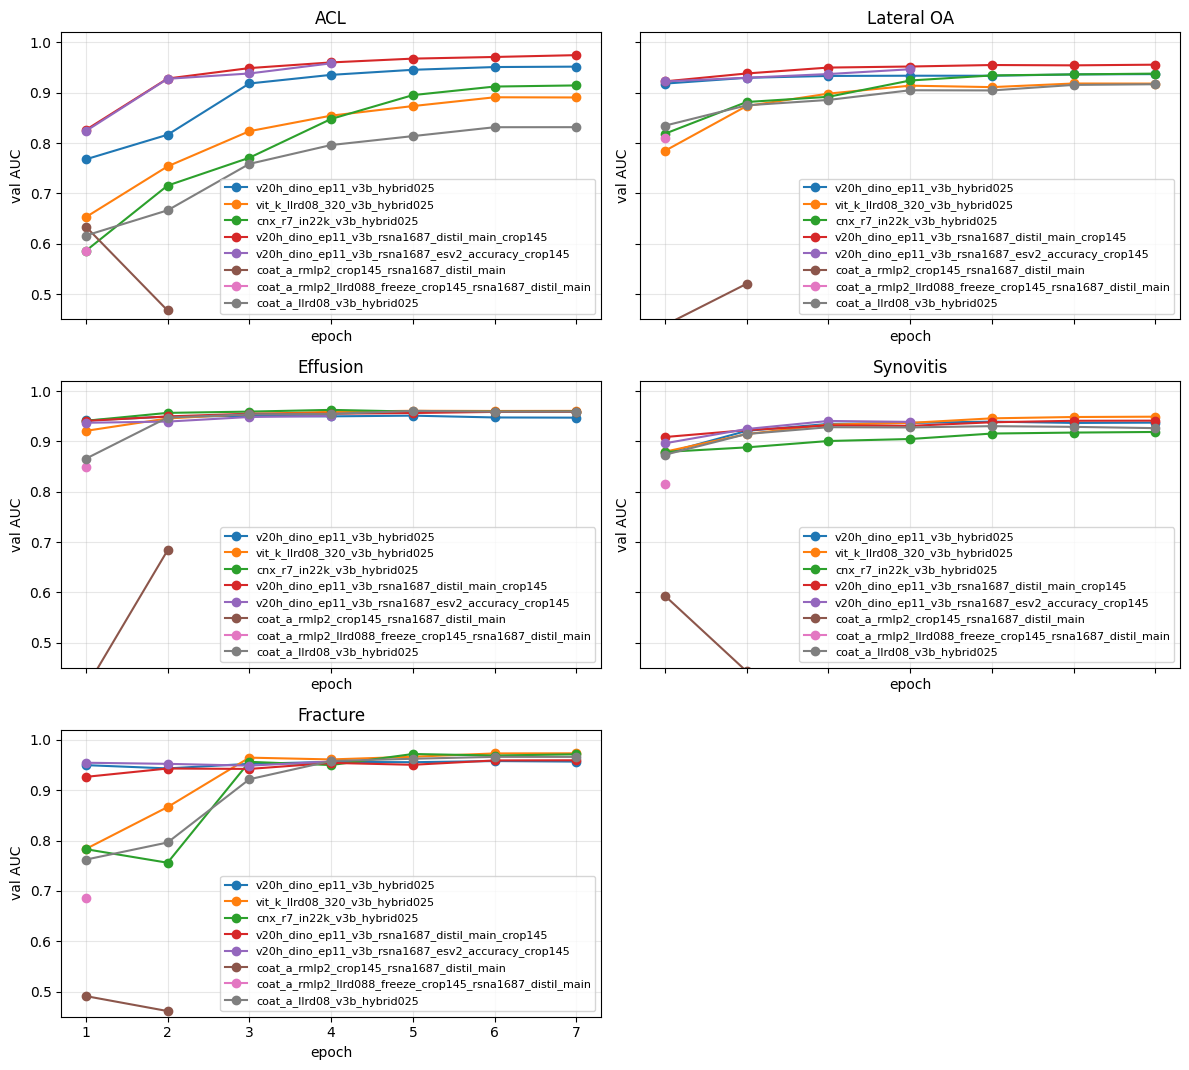

In [251]:
tgts = [t for t in FOCUS if any(f"auc_{t}" in r["hist"].columns for r in runs)]
n = max(len(tgts), 1)
ncols = 2
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.6 * nrows), sharex=True, sharey=True)
if nrows == 1 and ncols == 1:
    axes = [axes]
elif nrows == 1 or ncols == 1:
    axes = list(axes)
else:
    axes = [ax for row in axes for ax in row]
emax = max(int(r["hist"]["epoch"].max()) for r in runs)
for ax, tgt in zip(axes, tgts):
    col = f"auc_{tgt}"
    for r in runs:
        h = r["hist"].sort_values("epoch")
        if col not in h.columns:
            continue
        ax.plot(h.epoch, h[col], **line_kw(r))
    ax.set_title(tgt)
    ax.set_ylim(0.45, 1.02)
    ax.set_xticks(range(1, emax + 1))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    ax.set_xlabel("epoch")
    ax.set_ylabel("val AUC")
for ax in axes[len(tgts):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


## Même subset ? (train_uids)

Les YAML subset partagent `train_frac_seed: 42`. L'overlap doit être 100 %.


In [252]:
uid_sets = {r["name"]: set(r["uids"]) for r in runs if r["uids"]}
if len(uid_sets) < 2:
    print("pas assez de train_uids.txt pour comparer")
else:
    names = list(uid_sets)
    ref_n = names[0]
    sref = uid_sets[ref_n]
    ok = True
    print(f"ref UIDs : {run_label(ref_n)} ({len(sref)})")
    for n in names[1:]:
        s = uid_sets[n]
        print(
            f"  {run_label(n)}: {len(s)} | "
            f"inter {len(sref & s)} | seulement ref {len(sref - s)} | "
            f"seulement run {len(s - sref)}"
        )
        if s != sref:
            ok = False
    if ok:
        print("OK : exactement les memes etudes train")
    else:
        print("ATTENTION : subsets differents, la comparaison d'archi n'est plus propre")


ref UIDs : v20h_dino_ep11_v3b_hybrid025 (1687)
  cnx_r7_in22k_v3b_hybrid025: 1687 | inter 1687 | seulement ref 0 | seulement run 0
  v20h_dino_ep11_v3b_rsna1687_distil_main_crop145: 1687 | inter 583 | seulement ref 1104 | seulement run 1104
  v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145: 1687 | inter 583 | seulement ref 1104 | seulement run 1104
  coat_a_rmlp2_crop145_rsna1687_distil_main: 1687 | inter 583 | seulement ref 1104 | seulement run 1104
  coat_a_rmlp2_llrd088_freeze_crop145_rsna1687_distil_main: 1687 | inter 583 | seulement ref 1104 | seulement run 1104
  coat_a_llrd08_v3b_hybrid025: 1687 | inter 1687 | seulement ref 0 | seulement run 0
ATTENTION : subsets differents, la comparaison d'archi n'est plus propre


## Sanity gold du `best.pt` (si le run est fini)

`gold_sanity.json` n'est écrit qu'à la **fin** du script. Pendant l'entraînement,
utiliser la courbe `gold_macro_auc` ci-dessus.


v20h_dino_ep11_v3b_hybrid025: macro-AUC gold 0.9124  (best epoch 7)
vit_k_llrd08_320_v3b_hybrid025: pas encore de gold_sanity.json
cnx_r7_in22k_v3b_hybrid025: macro-AUC gold 0.8910  (best epoch 7)
v20h_dino_ep11_v3b_rsna1687_distil_main_crop145: pas encore de gold_sanity.json
v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145: macro-AUC gold 0.9088  (best epoch 4)
coat_a_rmlp2_crop145_rsna1687_distil_main: pas encore de gold_sanity.json
coat_a_rmlp2_llrd088_freeze_crop145_rsna1687_distil_main: pas encore de gold_sanity.json
coat_a_llrd08_v3b_hybrid025: macro-AUC gold 0.8591  (best epoch 7)


,subset_v20h_dino_ep11_v3b_hybrid025,subset_cnx_r7_in22k_v3b_hybrid025,subset_v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145,subset_coat_a_llrd08_v3b_hybrid025,d_subset_cnx_r7_in22k_v3b_hybrid025,d_subset_v20h_dino_ep11_v3b_rsna1687_esv2_accuracy_crop145,d_subset_coat_a_llrd08_v3b_hybrid025
ACL,0.973,0.951,0.971,0.843,-0.022,-0.002,-0.130
MCL,0.900,0.714,0.868,0.698,-0.186,-0.032,-0.202
Medial Meniscus,0.940,0.965,0.919,0.881,0.025,-0.020,-0.059
Lateral Meniscus,0.882,0.861,0.866,0.834,-0.021,-0.016,-0.048
Medial OA,0.998,0.978,0.984,0.977,-0.020,-0.014,-0.022
Lateral OA,0.826,0.797,0.857,0.810,-0.029,0.031,-0.015
PF OA,0.829,0.803,0.840,0.758,-0.026,0.012,-0.071
Effusion,0.963,0.983,0.995,0.934,0.020,0.032,-0.029
Synovitis,0.783,0.786,0.790,0.795,0.004,0.007,0.012
Baker's,0.993,0.991,0.982,0.966,-0.002,-0.011,-0.027


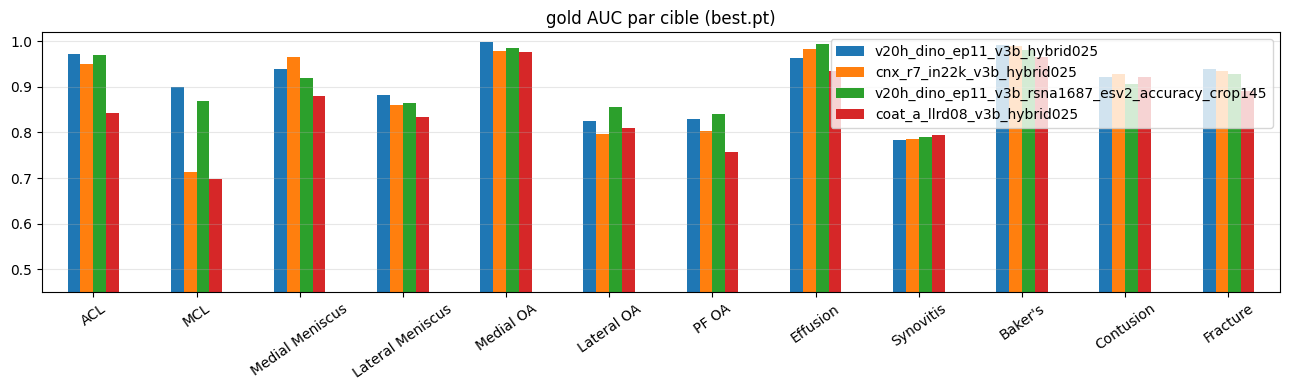

In [253]:
gcols = {}
for r in runs:
    if not r["gold"]:
        print(f"{r['label']}: pas encore de gold_sanity.json")
        continue
    g = r["gold"]
    print(f"{r['label']}: macro-AUC gold {g['macro_auc']:.4f}  (best epoch {g.get('epoch', '?')})")
    gcols[r["name"]] = pd.Series(g["per_target"])
if gcols:
    gdf = pd.DataFrame(gcols).reindex(TARGETS)
    if REF in gdf.columns:
        for c in list(gdf.columns):
            if c != REF:
                gdf[f"d_{c}"] = gdf[c] - gdf[REF]
    display(gdf.round(3))
    plot_g = gdf[[r["name"] for r in runs if r["name"] in gdf.columns]].rename(
        columns={r["name"]: r["label"] for r in runs if r["name"] in gdf.columns}
    )
    plot_g.plot(kind="bar", figsize=(13, 4), rot=35, title="gold AUC par cible (best.pt)")
    plt.ylim(0.45, 1.02)
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


## Comment lire

1. **Val macro-AUC** : pilote le checkpoint. Δ &lt; 0,01 vs la REF (ViT-k 224) → pas de gagnant.
2. **Spécialiste** : têtes en gras / courbes FOCUS, où le 320 bat la REF de plus de 0,01.
   C'est le critère d'ensemble, pas la macro.
3. **320 vs 224** : même recette. Un gain n'existe que si Δ val **et** Δ gold &gt; 0,01. Le suivi epoch-égale compare CoAt-a 320 à son parent 224.
4. **Gold** : n=58, bruité. Ne jamais piloter dessus.

Pour rafraîchir : **re-exécuter à partir de Load**. Pour changer l'analyse : **`RUNS`**.
